<a href="https://colab.research.google.com/github/uddipta2004/Brain-MRI-Image-Segmentation/blob/main/Potato_Leaf_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix
import seaborn as sns


In [2]:
data_dir = "/content/drive/MyDrive/internship.gu/POTATO/PotatoPlants"
image_size = (128,128)

In [3]:
def extract_color_histogram(image):
    hist_b = cv2.calcHist([image],[0],None,[32],[0,256])
    hist_g = cv2.calcHist([image],[1],None,[32],[0,256])
    hist_r = cv2.calcHist([image],[2],None,[32],[0,256])
    hist = np.concatenate([hist_b,hist_g,hist_r]).flatten()
    hist = hist / hist.sum()
    return hist.flatten()

def load_images_color_histogram(data_dir):
  features = []
  labels = []
  for label in os.listdir(data_dir):
    class_dir = os.path.join(data_dir,label)
    for img_file in os.listdir(class_dir):
            img_path = os.path.join(class_dir, img_file)
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.resize(img, image_size)
                hist_feat = extract_color_histogram(img)
                features.append(hist_feat)
                labels.append(label)

                flipped=cv2.flip(img, 1)
                hist_feat_flip = extract_color_histogram(flipped)
                features.append(hist_feat_flip)
                labels.append(label)

  return np.array(features), np.array(labels)
features, labels = load_images_color_histogram(data_dir)
print("Total samples after augmentation:", len(features))
le = LabelEncoder()
y_encoded = le.fit_transform(labels)
X_train, X_test, y_train, y_test = train_test_split(features, y_encoded, test_size=0.2, random_state=42)

print("Train size:",len(X_train), "Test size:",len(X_test))





Total samples after augmentation: 4264
Train size: 3411 Test size: 853


In [4]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
print("Training completed")

Training completed


Classification Report:
                       precision    recall  f1-score   support

Potato___Early_blight       0.99      0.98      0.99       371
 Potato___Late_blight       0.97      1.00      0.98       428
     Potato___healthy       1.00      0.89      0.94        54

             accuracy                           0.98       853
            macro avg       0.99      0.96      0.97       853
         weighted avg       0.98      0.98      0.98       853



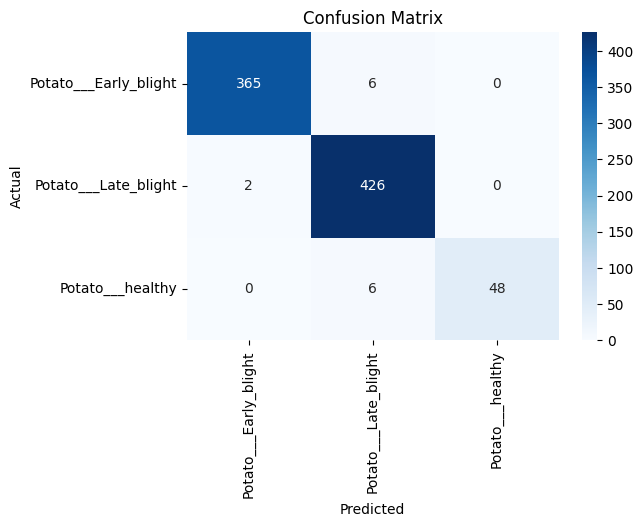

In [5]:
y_pred = model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [6]:
def predict_unseen(image_path):
  img = cv2.imread(image_path)
  img = cv2.resize(img, image_size)
  hist_feat = extract_color_histogram(img).reshape(1, -1)
  pred = model.predict(hist_feat)
  pred_label = le.inverse_transform(pred)[0]
  print("Predicted classes:", pred_label)
  plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  plt.title("Predicted:" + pred_label)
  plt.axis('off')
  plt.show()

Predicted classes: Potato___healthy


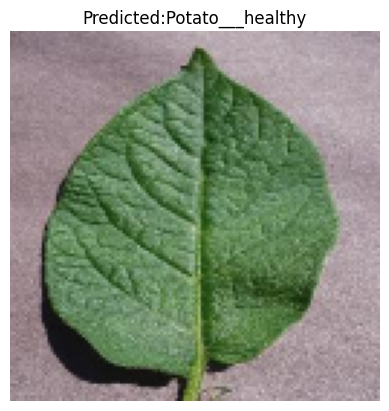

In [9]:
predict_unseen("/content/drive/MyDrive/internship.gu/POTATO/Prediction/Healthy/22322780-95b4-4b45-b626-26b22965d55e___RS_HL 1880.JPG")

Predicted classes: Potato___Late_blight


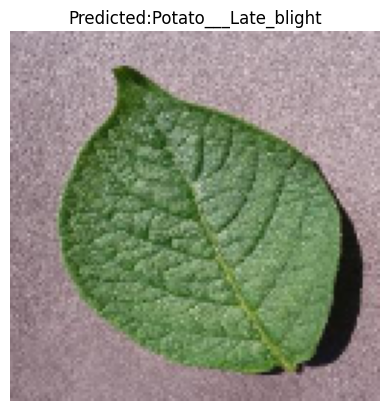

In [10]:
predict_unseen("//content/drive/MyDrive/internship.gu/POTATO/Prediction/Healthy/30937333-8898-4634-8c00-af57d3020ba6___RS_HL 1922.JPG")